# PRÁCTICA PYTHON
## Adrià Olomí Farré | 18-11-2026
### Este es un notebook con las funciones básicas que se piden en la práctica.

# Comprobación de tipos

In [73]:
!uv run mypy src/

src/trafic_fines/cache.py:198: error: Signature of "exists" incompatible with supertype "Cache"  [override]
src/trafic_fines/cache.py:198: note:      Superclass:
src/trafic_fines/cache.py:198: note:          def exists(self, name: str) -> bool
src/trafic_fines/cache.py:198: note:      Subclass:
src/trafic_fines/cache.py:198: note:          def exists(self, url: str, **kwargs: Any) -> bool
src/trafic_fines/cache.py:207: error: Signature of "load" incompatible with supertype "Cache"  [override]
src/trafic_fines/cache.py:207: note:      Superclass:
src/trafic_fines/cache.py:207: note:          def load(self, name: str) -> str
src/trafic_fines/cache.py:207: note:      Subclass:
src/trafic_fines/cache.py:207: note:          def load(self, url: str, **kwargs: Any) -> str
src/trafic_fines/cache.py:220: error: Signature of "how_old" incompatible with supertype "Cache"  [override]
src/trafic_fines/cache.py:220: note:      Superclass:
src/trafic_fines/cache.py:220: note:          def how_old(sel

Se observan 4 errores que corresponden al cambio de atributos de la cabecera de métodos.
El cambio es name (clase padre) -> url (clase hija)
Dejo estos errores porque nombrar el atributo url me facilita la implementación. Se discutió en un hilo del Campus Virtual.

# 1. Módulo Caché

### Importaciones

In [75]:
from trafic_fines.cache import Cache, CacheURL, CacheError

### Crear objeto de la clase

In [76]:
c = CacheURL("olomi_url_test_dir", 12)
print(str(c))

AppName: olomi_url_test_dir , CacheDir: /home/adria.olomi@local.eurecat.org/.my_cache/olomi_url_test_dir , Obsolescence: 12


### Realizar un get a la url indicada. En este caso, a un fichero pequeño de multas.

In [89]:
raiz = "https://datos.madrid.es/"
extension = "dataset/210104-0-multas-circulacion-detalle/resource/210104-388-multas-circulacion-detalle/download/210104-388-multas-circulacion-detalle.csv" 
url = raiz + extension.lstrip("/")
c.get(url)

'N�MERO;IMPORTE        \n000000028;000014730,00\n'

In [86]:
# Cada vez que se llama sin borrar la caché, el valor debería de aumentar. Son milisegundos.
print(c.how_old(url))

83406.51273727417


### Comprobar si existen los datos en caché

In [91]:
c.exists(url) # debería dar True

True

### Borrar el contenido de la caché

In [92]:
c.clear()

In [93]:
c.exists(url) # debería dar False

False

# 2. Módulo MadridFines

### Importaciones

In [74]:
from trafic_fines.madridFines import MadridFines, MadridError

### Crear objeto de la clase

In [64]:
# Crear objeto de la classe MadridFines
m = MadridFines(app_name="Olomi", obsolescence=2)
# Vaciar la caché, para empezar con un entorno limpio
m.clean_cache()
# Ver info de la clase
str(m)

' , Data: Empty DataFrame\nColumns: []\nIndex: [] , Loaded: []'

### Filtraje del df

In [65]:
## ANTES DEL FILTRAJE
# Cargar dataset
df = MadridFines.load(year=2024, month=9, cacheurl=m.cacheurl)
df.columns

Index(['CALIFICACION', 'LUGAR', 'MES', 'ANIO', 'HORA', 'IMP_BOL', 'DESCUENTO',
       ' PUNTOS', 'DENUNCIANTE', 'HECHO-BOL', 'VEL_LIMITE', 'VEL_CIRCULA ',
       'COORDENADA-X',
       'COORDENADA-Y                                                                                                                                                      '],
      dtype='str')

In [66]:
## DESPUÉS DEL FILTRAJE
MadridFines.clean(df) 
df.columns

Entrando al método clean...


Index(['CALIFICACION', 'LUGAR', 'MES', 'ANIO', 'HORA', 'IMP_BOL', 'DESCUENTO',
       'PUNTOS', 'DENUNCIANTE', 'HECHO-BOL', 'VEL_LIMITE', 'VEL_CIRCULA',
       'COORDENADA-X',
       'COORDENADA-Y                                                                                                                                          ',
       'FECHA'],
      dtype='str')

### Trabajando con múltiples datasets

In [67]:
# Cargar varios datasets
m.add(year=2024, month=9)
m.add(year=2024, month=10)
m.add(year=2024, month=11)
m.add(year=2025, month=1)
m.add(year=2025, month=4)
m.add(year=2025, month=6)

Entrando al método clean...


/home/adria.olomi@local.eurecat.org/Documents/PERSONAL/UCM/trafic-fines/src/trafic_fines/madridFines.py:99: DtypeWarning: Columns (12: COORDENADA-X) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(content, sep =';', encoding = 'latin1')


Entrando al método clean...
Entrando al método clean...
Entrando al método clean...
Entrando al método clean...
Entrando al método clean...


In [68]:
# Cargar un dataset ya importado
m.add(year=2024, month=9)

El dataset ya estaba previamente importado


### Distribución de multas por calificación, mes y año

In [39]:
m.fines_calification()

,CALIFICACION,GRAVE,LEVE,MUY GRAVE
MES,ANIO,,,
1,2025,136708,96580,764
4,2025,125495,85664,705
6,2025,136625,97999,788
9,2024,145634,94332,759
10,2024,158501,106001,845
11,2024,156519,96829,765


### Resumen con el importe total (máximo y mínimo) recaudado por mes y año

In [69]:
m.total_payment()

,,PRECIO_MIN,PRECIO_MAX
MES,ANIO,,
1,2025,16661590.0,33323180.0
4,2025,15066000.0,30132000.0
6,2025,16258575.0,32517150.0
9,2024,16852380.0,33704760.0
10,2024,18871970.0,37743940.0
11,2024,18381030.0,36762060.0


### Gráfico de líneas que muestra la evolución del número de multas a lo largo de las horas del día

In [70]:
nombre_figura = "test.png"
m.fines_hour(fig_name=nombre_figura)

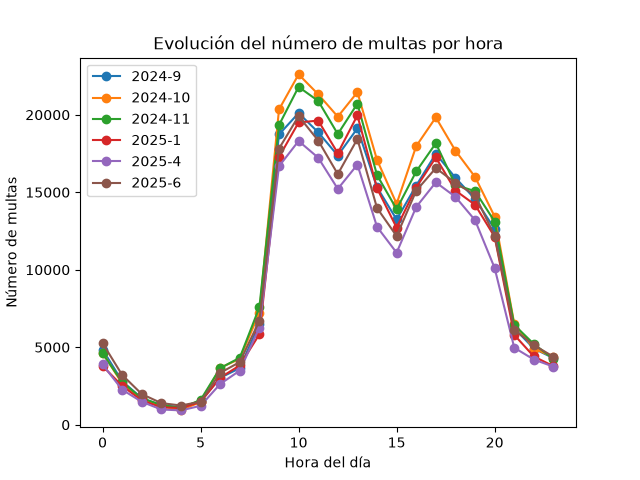

In [71]:
from IPython.display import display, Image
display(Image(filename=nombre_figura))